# 01 · EDA — khảo sát dữ liệu Speech Commands v0.02

Mục tiêu: hiểu dữ liệu **trước khi** chọn tham số tiền xử lý và mô hình.

**Những điều đã biết về nguồn dữ liệu** (Warden, 2018, *Speech Commands*, arXiv:1804.03209):
- 105,829 clip, 35 từ, **2,618 người nói**; WAV 16 kHz / 16-bit / mono, dài ≤ 1 giây.
- Thu bằng **trình duyệt qua mic điện thoại/laptop** ở nhà người đóng góp (có nhiễu, mic kém), nén OGG rồi đổi sang WAV.
- Mỗi clip là đoạn 1 giây **to nhất** trong bản thu 1.5 giây → từ nằm gần giữa clip. Clip có độ lớn trung bình |x| < 0.004 đã bị loại.
- Tên file `<mã người nói>_nohash_<k>.wav`; `validation_list.txt` / `testing_list.txt` chia **theo người nói** bằng hàm băm.
- Thư mục `_background_noise_` có 6 file nhiễu dài ~1 phút.

In [1]:
import os, sys, pathlib, warnings, time
p = pathlib.Path.cwd().resolve()
ROOT = next((c for c in [p, *p.parents] if (c / "config.py").exists()), None)
if ROOT is None:
    raise RuntimeError("Hãy mở notebook từ bên trong thư mục dự án (nơi có config.py).")
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)

import numpy as np
import matplotlib.pyplot as plt
import joblib
from config import Config, TARGET_WORDS
from speech import dataset as ds
from speech.features import utterance_features
from speech.plots import setup_style
setup_style()

cfg = Config()
N_JOBS = min(4, os.cpu_count() or 1)
print("Thư mục dự án :", ROOT)
print("Dữ liệu gốc   :", cfg.data.data_root)

Thư mục dự án : D:\2027\HTTM\speech_hmm_project_v4_hmmlearn\proj
Dữ liệu gốc   : D:\2027\HTTM\speech_hmm_project_v4_hmmlearn\proj\data\speech_commands_v0.02


In [2]:
# Tải dữ liệu (~2.3 GB) nếu chưa có. Trên Colab nên để dữ liệu ở đĩa cục bộ (/content), không để trên Drive.
if not (pathlib.Path(cfg.data.data_root) / "testing_list.txt").exists():
    ds.download_speech_commands(cfg.data.data_root, cfg.data.url)

## 1. Quy mô dữ liệu và chia theo người nói

In [3]:
items = ds.get_items(cfg, TARGET_WORDS)          # đã kiểm tra: người nói không trùng giữa các tập
print("Người nói trùng giữa các tập (phải = 0):", ds.verify_speaker_disjoint(items))

splits = ("train", "val", "test")
print(f"{'từ':>7} " + " ".join(f"{s:>7}" for s in splits))
for w in TARGET_WORDS:
    print(f"{w:>7} " + " ".join(f"{sum(1 for i in items if i['word']==w and i['split']==s):>7}" for s in splits))
for s in splits:
    print(f"số người nói trong {s:>5}: {len({i['speaker'] for i in items if i['split']==s})}")

Người nói trùng giữa các tập (phải = 0): {'train&val': 0, 'train&test': 0, 'val&test': 0}
     từ   train     val    test
     up    2948     350     425
   down    3134     377     406
   left    3037     352     412
  right    3019     363     396
số người nói trong train: 1906
số người nói trong   val: 233
số người nói trong  test: 229


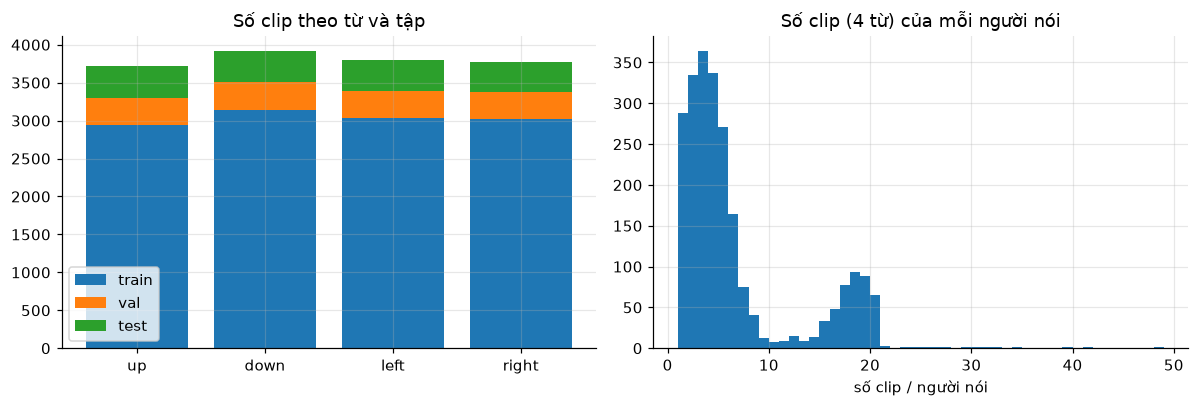

In [4]:
from collections import Counter
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
bottom = np.zeros(len(TARGET_WORDS))
for s in splits:
    v = np.array([sum(1 for i in items if i["word"] == w and i["split"] == s) for w in TARGET_WORDS])
    ax[0].bar(TARGET_WORDS, v, bottom=bottom, label=s); bottom += v
ax[0].set_title("Số clip theo từ và tập"); ax[0].legend()
per_spk = Counter(i["speaker"] for i in items)
ax[1].hist(list(per_spk.values()), bins=range(1, max(per_spk.values()) + 2), color="#1f77b4")
ax[1].set_title("Số clip (4 từ) của mỗi người nói"); ax[1].set_xlabel("số clip / người nói")
plt.tight_layout(); plt.show()

## 2. Thời lượng và độ lớn tín hiệu

In [5]:
from speech.evaluate import rms_dbfs
def clip_stats(it):
    y = ds.read_wav(it["path"])
    return dict(word=it["word"], split=it["split"], dur=len(y) / 16000, rms_db=rms_dbfs(y),
                peak=float(np.abs(y).max()), mean_abs=float(np.abs(y).mean()))

stats_file = pathlib.Path(cfg.data.cache_dir) / "eda_clip_stats.joblib"
stats_file.parent.mkdir(exist_ok=True)
if stats_file.exists():
    stats = joblib.load(stats_file)
else:
    stats = joblib.Parallel(n_jobs=N_JOBS, batch_size=128)(joblib.delayed(clip_stats)(i) for i in items)
    joblib.dump(stats, stats_file)
dur = np.array([s["dur"] for s in stats])
print(f"Số clip ngắn hơn 1 s: {np.mean(dur < 0.999):.1%} (thời lượng tối thiểu {dur.min():.2f} s)")

Số clip ngắn hơn 1 s: 9.3% (thời lượng tối thiểu 0.30 s)


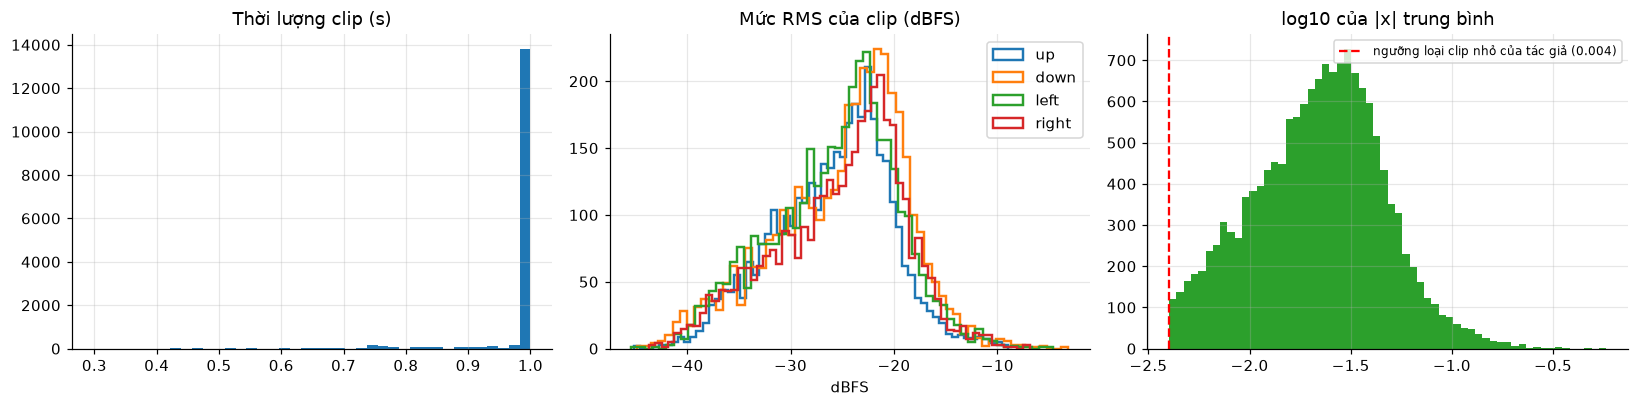

RMS clip (dBFS): phân vị 5/50/95 = [-36.6 -24.5 -16.6]


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].hist(dur, bins=40, color="#1f77b4"); ax[0].set_title("Thời lượng clip (s)")
for w in TARGET_WORDS:
    r = [s["rms_db"] for s in stats if s["word"] == w]
    ax[1].hist(r, bins=60, histtype="step", lw=1.6, label=w)
ax[1].set_title("Mức RMS của clip (dBFS)"); ax[1].set_xlabel("dBFS"); ax[1].legend()
ma = np.array([s["mean_abs"] for s in stats])
ax[2].hist(np.log10(ma), bins=60, color="#2ca02c")
ax[2].axvline(np.log10(0.004), color="r", ls="--", label="ngưỡng loại clip nhỏ của tác giả (0.004)")
ax[2].set_title("log10 của |x| trung bình"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()
r_all = np.array([s["rms_db"] for s in stats])
print("RMS clip (dBFS): phân vị 5/50/95 =", np.round(np.percentile(r_all, [5, 50, 95]), 1))

**So sánh với mic của bạn.** Nếu đã chạy `python tools/record_samples.py`, các bản thu nằm ở `data/my_recordings/<từ>/`.
Biểu đồ dưới đặt mức RMS của bản thu cạnh dữ liệu gốc: nếu mic của bạn nằm lệch hẳn về bên trái (nhỏ hơn nhiều)
thì tỷ số tín hiệu/nhiễu thấp và cần tăng âm lượng mic trong Windows hoặc nói gần mic hơn.

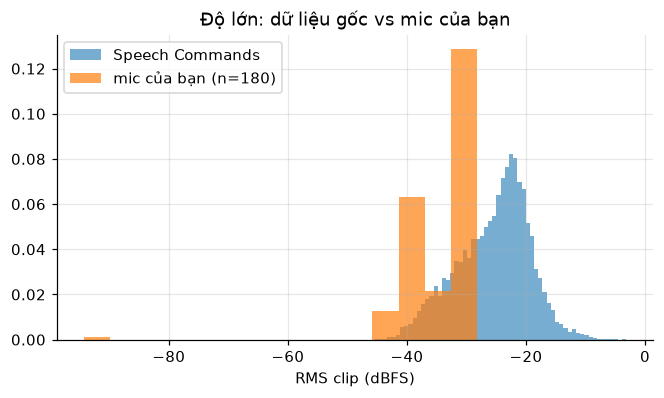

In [7]:
MY_DIR = ROOT / "data" / "my_recordings"
my_files = sorted(MY_DIR.glob("*/*.wav")) if MY_DIR.exists() else []
if my_files:
    my_db = [rms_dbfs(ds.read_wav(str(f))) for f in my_files]
    plt.figure(figsize=(7, 3.6))
    plt.hist(r_all, bins=60, density=True, alpha=0.6, label="Speech Commands")
    plt.hist(my_db, bins=15, density=True, alpha=0.7, label=f"mic của bạn (n={len(my_db)})")
    plt.xlabel("RMS clip (dBFS)"); plt.legend(); plt.title("Độ lớn: dữ liệu gốc vs mic của bạn"); plt.show()
else:
    print("Chưa có bản thu riêng. Chạy: python tools/record_samples.py")

**Nền ồn và SNR.** Chỉ số quan trọng nhất để biết mic của bạn có "khó" hơn dữ liệu gốc không: mức tiếng nói (phân vị 90 năng lượng khung trong đoạn
được cắt), nền ồn (phân vị 10 của cả clip) và SNR = hiệu hai số đó. Nền ồn/SNR chỉ phụ thuộc môi trường + thiết bị, không phụ thuộc giọng nói.

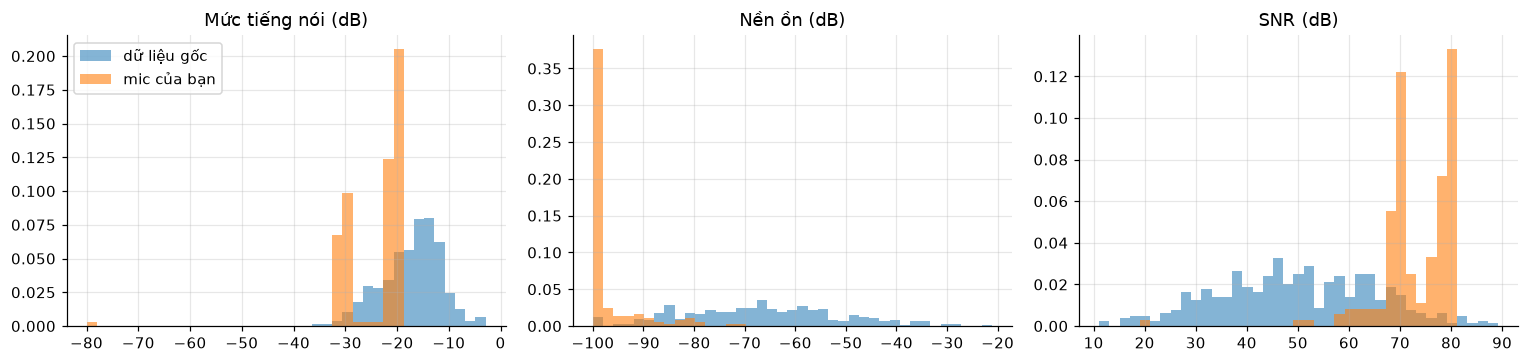

SNR trung vị: dữ liệu gốc 49.5 dB | mic của bạn 73.2 dB | nền ồn: -67.1 vs -100.0 dBFS
Nếu SNR của mic thấp hơn nhiều: tăng Input volume trong Windows, nói gần mic hơn, tắt noise suppression/AGC.


In [8]:
from speech.endpoint import frame_energy_db
def level_stats(y):
    f, seg = utterance_features(y, cfg, return_segment=True)
    if f is None:
        return None
    e_all = frame_energy_db(y, 16000, 25, 10)
    e_seg = frame_energy_db(y[seg[0]:seg[1]], 16000, 25, 10)
    speech, noise = np.percentile(e_seg, 90), np.percentile(e_all, 10)
    return speech, noise, speech - noise

if my_files:
    rs = np.random.default_rng(0)
    sample = [items[j] for j in rs.permutation(len(items))[:400]]
    A = np.array([r for r in (level_stats(ds.read_wav(i["path"])) for i in sample) if r])
    B = np.array([r for r in (level_stats(ds.read_wav(str(f))) for f in my_files) if r])
    fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
    for k, ttl in enumerate(["Mức tiếng nói (dB)", "Nền ồn (dB)", "SNR (dB)"]):
        bins = np.linspace(min(A[:, k].min(), B[:, k].min()), max(A[:, k].max(), B[:, k].max()), 40)
        ax[k].hist(A[:, k], bins=bins, density=True, alpha=0.55, label="dữ liệu gốc")
        ax[k].hist(B[:, k], bins=bins, density=True, alpha=0.6, label="mic của bạn"); ax[k].set_title(ttl)
    ax[0].legend(); plt.tight_layout(); plt.show()
    print(f"SNR trung vị: dữ liệu gốc {np.median(A[:, 2]):.1f} dB | mic của bạn {np.median(B[:, 2]):.1f} dB "
          f"| nền ồn: {np.median(A[:, 1]):.1f} vs {np.median(B[:, 1]):.1f} dBFS")
    print("Nếu SNR của mic thấp hơn nhiều: tăng Input volume trong Windows, nói gần mic hơn, tắt noise suppression/AGC.")

In [9]:
bank = ds.load_noise_bank(cfg.data.data_root)
for name, y in bank.items():
    print(f"{name:>20}: {len(y)/16000:5.1f} s, RMS = {rms_dbfs(y):6.1f} dBFS")

    doing_the_dishes:  95.2 s, RMS =  -28.5 dBFS
       dude_miaowing:  61.8 s, RMS =  -48.0 dBFS
       exercise_bike:  61.3 s, RMS =  -32.6 dBFS
          pink_noise:  60.0 s, RMS =   -9.6 dBFS
         running_tap:  61.2 s, RMS =  -23.3 dBFS
         white_noise:  60.0 s, RMS =   -9.6 dBFS


## 3. Bộ cắt đoạn tiếng nói (endpoint) và độ dài chuỗi đặc trưng

Dữ liệu có phần im lặng/nhiễu ở hai đầu và từ nằm ở vị trí khác nhau. Ta cắt đoạn chứa từ bằng **cùng một hàm**
(`speech.endpoint.find_speech_segment`) ở huấn luyện, đánh giá và demo, rồi mới trích MFCC.
Độ dài chuỗi (số khung 10 ms) cho biết nên dùng bao nhiêu trạng thái HMM: quy ước thường dùng là mỗi trạng thái
nhận khoảng 5–10 khung trở lên.

In [10]:
rng = np.random.default_rng(0)
SAMPLE = 300
seg_ms = {w: [] for w in TARGET_WORDS}; T_fr = {w: [] for w in TARGET_WORDS}
rej = {}; examples = {}
for w in TARGET_WORDS:
    sel = [i for i in items if i["word"] == w and i["split"] == "train"]
    sel = [sel[j] for j in rng.permutation(len(sel))[:SAMPLE]]
    n_rej = 0
    for it in sel:
        y = ds.read_wav(it["path"])
        f, seg = utterance_features(y, cfg, return_segment=True)
        if f is None:
            n_rej += 1; continue
        seg_ms[w].append((seg[1] - seg[0]) / 16.0); T_fr[w].append(len(f))
        examples.setdefault(w, (y, seg))
    rej[w] = n_rej / len(sel)
print("Tỷ lệ clip bị endpoint loại:", {w: f"{v:.1%}" for w, v in rej.items()})
print(f"{'từ':>7} {'T trung vị':>11} {'T 5%':>6} {'T 95%':>6}   khung/trạng thái khi N=4,5,6,8")
for w in TARGET_WORDS:
    t = np.array(T_fr[w])
    print(f"{w:>7} {np.median(t):>11.0f} {np.percentile(t,5):>6.0f} {np.percentile(t,95):>6.0f}   "
          + ", ".join(f"{np.median(t)/n:.1f}" for n in (4, 5, 6, 8)))

Tỷ lệ clip bị endpoint loại: {'up': '3.7%', 'down': '1.7%', 'left': '1.7%', 'right': '0.7%'}
     từ  T trung vị   T 5%  T 95%   khung/trạng thái khi N=4,5,6,8
     up          46     27     71   11.5, 9.2, 7.7, 5.8
   down          62     37     86   15.5, 12.4, 10.3, 7.8
   left          61     31     87   15.2, 12.2, 10.2, 7.6
  right          59     34     84   14.8, 11.8, 9.8, 7.4


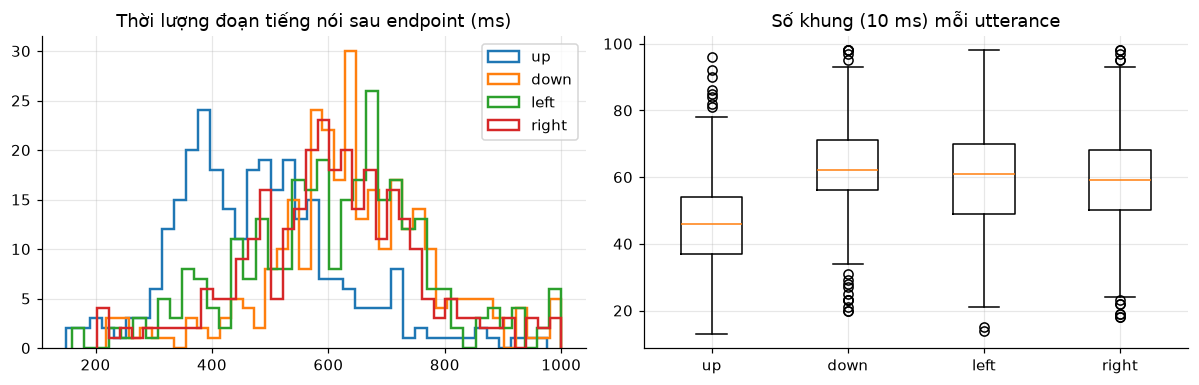

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for w in TARGET_WORDS:
    ax[0].hist(seg_ms[w], bins=40, histtype="step", lw=1.6, label=w)
ax[0].set_title("Thời lượng đoạn tiếng nói sau endpoint (ms)"); ax[0].legend()
ax[1].boxplot([T_fr[w] for w in TARGET_WORDS]); ax[1].set_xticks(range(1, len(TARGET_WORDS) + 1), TARGET_WORDS)
ax[1].set_title("Số khung (10 ms) mỗi utterance"); plt.tight_layout(); plt.show()

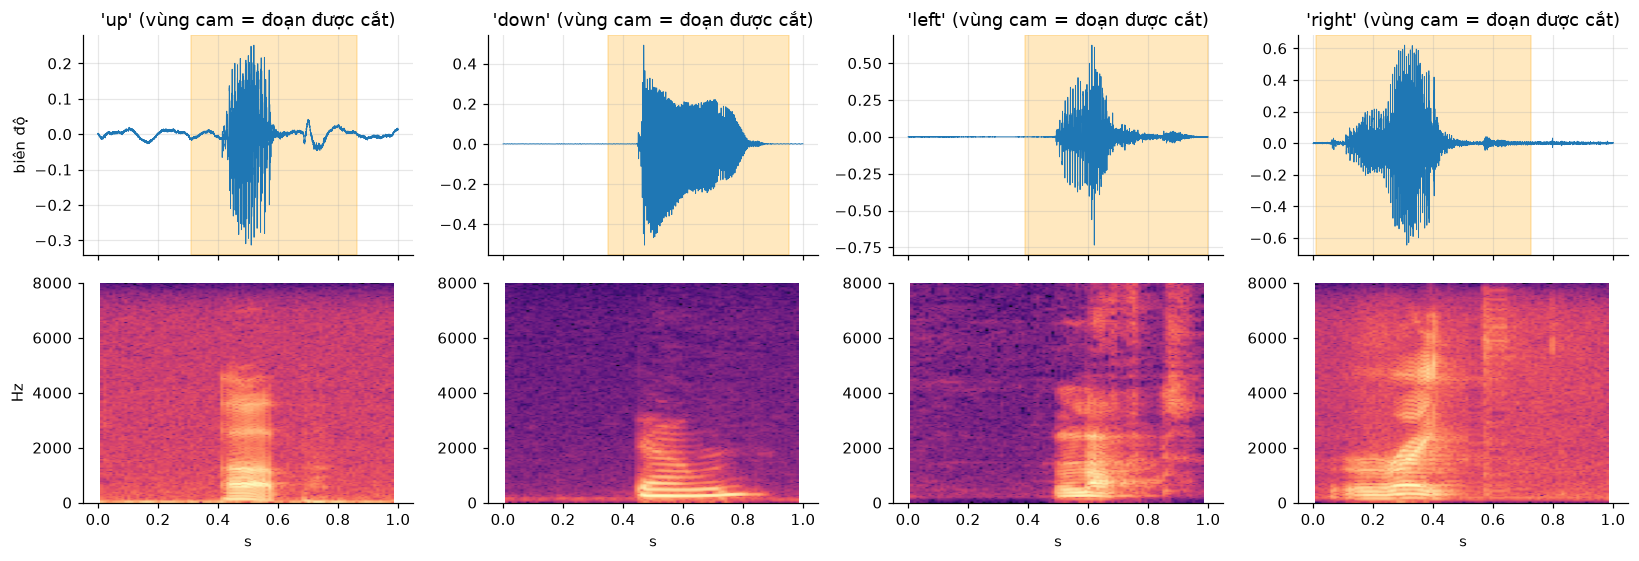

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(15, 5.2), sharex="col")
for k, w in enumerate(TARGET_WORDS):
    y, (a, b) = examples[w]
    t = np.arange(len(y)) / 16000
    axes[0, k].plot(t, y, lw=0.6); axes[0, k].axvspan(a / 16000, b / 16000, color="orange", alpha=0.25)
    axes[0, k].set_title(f"'{w}' (vùng cam = đoạn được cắt)")
    axes[1, k].specgram(y, NFFT=400, Fs=16000, noverlap=240, cmap="magma")
    axes[1, k].set_xlabel("s"); axes[1, k].grid(False)
axes[0, 0].set_ylabel("biên độ"); axes[1, 0].set_ylabel("Hz")
plt.tight_layout(); plt.show()

## Kết luận cần ghi nhớ
- Chia theo người nói đã được kiểm tra: tập test chứa người **chưa từng xuất hiện** khi huấn luyện.
- Độ lớn clip trải rộng; dữ liệu gốc đã loại clip quá nhỏ, nên mic quá yếu sẽ nằm ngoài vùng dữ liệu → hãy so mức dBFS của mic bạn ở trên.
- Chuẩn hóa CMVN theo từng utterance giúp mô hình ít phụ thuộc vào âm lượng và đặc tính mic, nhưng **không** loại bỏ nhiễu.
- Chọn số trạng thái sao cho `khung/trạng thái` ≳ 5 với từ ngắn nhất (`up`).